# Supervised models

Notebook 02 showed that the data are a collection of studies, and that the usual random cross-validation partly
measures how well a model recognises a study. This notebook starts with the question that decides how to read every
later score: **how much does a model beat a trivial predictor on a study it has never seen, and is it the same for
every study?** Only then does it compare models.

Protocols, always on identical folds (`src.evaluation`): `random` (shuffled, stratified), `grouped` (5 folds of whole
studies) and `loso` (one study held out at a time, studies with at least 20 rows). Two scores are reported:
**R2**, which compares with the mean of the *test* fold (a value nobody knows beforehand), and **skill**
= 1 - SSE(model) / SSE(mean of the training fold), which is exactly 0 for a model that predicts the training mean
and positive when it does better.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

warnings.filterwarnings("ignore")
PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "src" / "config.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))

from src.baselines import baseline_models
from src.cleaning import clean_dataframe
from src.config import FIGURES_DIR, RESULTS_DIR, SCALED_CLIP, TARGETS
from src.evaluation import ALL_PROTOCOLS, ModelSpec, compare_models, per_study_scores, summarize, make_folds
from src.loading import load_raw
from src.models import GroupTunedRidge
from src.preprocessing import build_preprocessor, feature_spec

FIG = FIGURES_DIR / "supervised_models"
FIG.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

clean = clean_dataframe(load_raw())
print(clean.shape, "| studies held out one at a time:", len(make_folds(clean, "loso")))

(1652, 60) | studies held out one at a time: 15


## 1. Baselines and per-study scores

### 1.1 Reference scores under the three protocols

Two baselines (`src.baselines`): the **global mean** of the training fold, and the **study mean** (the mean of the
same study seen in training; on a study that was held out it can only fall back to the global mean). Two models: a
random forest and a ridge regression, the latter in two versions: the first one as it was before a defect was found
(scaled features unbounded, fixed penalty, see 1.4) and the corrected one (features clipped, penalty chosen by cross-validation
over whole studies inside the training data).

In [2]:
models = baseline_models() + [
    ModelSpec("ridge, no clip (before the fix)", "linear", lambda: Ridge(alpha=1.0), clip=None),
    ModelSpec("ridge, clipped, penalty tuned by study CV", "linear", GroupTunedRidge, uses_source=True),
    ModelSpec("random forest", "tree", lambda: RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1)),
]
results = compare_models(clean, models, protocols=ALL_PROTOCOLS)
results.to_csv(RESULTS_DIR / "03_baselines_folds.csv", index=False)
summary = summarize(results)
summary.to_csv(RESULTS_DIR / "03_baselines_summary.csv", index=False)

order = [m.name for m in models]
for metric in ("skill_mean", "r2_mean"):
    table = summary.pivot_table(index=["target", "model"], columns="protocol", values=metric)
    table = table[["random", "grouped", "loso"]].reindex(order, level="model")
    print(f"\n{metric} (mean over folds; loso = mean over held-out studies)")
    print(table.round(2).to_string())


skill_mean (mean over folds; loso = mean over held-out studies)
protocol                                                         random  grouped  loso
target                model                                                           
charpy_toughness_j    global_mean                                  0.00     0.00  0.00
                      study_mean                                   0.20     0.00  0.00
                      ridge, no clip (before the fix)              0.60    -0.62 -2.46
                      ridge, clipped, penalty tuned by study CV    0.54    -0.22 -0.02
                      random forest                                0.83     0.16  0.22
elongation_pct        global_mean                                  0.00     0.00  0.00
                      study_mean                                   0.30     0.00  0.00
                      ridge, no clip (before the fix)              0.66    -0.44 -1.47
                      ridge, clipped, penalty tuned by study CV  

**Your conclusions:**

- **R2 on an unseen study mostly measures the study's offset.** The training-mean predictor, which learns nothing, scores R2 = -0.37 on yield strength and UTS, -0.68 on elongation, -0.70 on reduction of area and -0.65 on Charpy toughness in the grouped protocol, and down to -2.8 for the ductility targets when one study is held out. A forest at R2 = 0.05 on yield strength is therefore well above the trivial predictor. (My earlier reading of the smoke test, "R2 close to 0 means almost nothing is explained on a new study", was wrong: it had no reference point.)
- **Against the training mean, the forest has a modest but real skill on unseen studies**: yield strength 0.28 (grouped) / 0.30 (leave-one-study-out), UTS 0.42 / 0.39, Charpy toughness 0.16 / 0.22, reduction of area 0.29 / 0.09, elongation 0.28 / -0.06. Strength is the most predictable; elongation is not reliably better than the mean once a single study is held out.
- **The random protocol is far more flattering**: the forest's skill is 0.74-0.86 there, against 0.16-0.42 on unseen studies.
- **The ridge, before the fix, is worse than the mean on unseen studies** (skill between -0.62 and -2.46 on yield strength, UTS and Charpy depending on the protocol): this came from the preprocessing, see 1.4.
- **After the fix (features clipped, penalty chosen by cross-validation over studies inside the training data), the ridge is about as good as the mean**: yield strength 0.02 (grouped) / 0.01 (leave-one-study-out), UTS 0.34 / 0.15, Charpy -0.22 / -0.02, elongation -0.01 / -0.38, reduction of area 0.48 / -0.23. In leave-one-study-out it stays below the forest on every target. The grouped score for reduction of area (0.48, above the forest's 0.29) against -0.23 when studies are held out one at a time shows how much the 5-fold grouped protocol depends on which studies share a fold.


### 1.2 How much of the random score is only the study?

In [3]:
random_skill = summary[summary["protocol"] == "random"].pivot_table(index="target", columns="model", values="skill_mean")
share = pd.DataFrame({
    "study_mean": random_skill["study_mean"],
    "random_forest": random_skill["random forest"],
    "share_of_forest_skill_%": (100 * random_skill["study_mean"] / random_skill["random forest"]).round(0),
}).round(2)
share.to_csv(RESULTS_DIR / "03_study_share_of_random_skill.csv")
print("random protocol, skill:")
print(share.to_string())

random protocol, skill:
                       study_mean  random_forest  share_of_forest_skill_%
target                                                                   
charpy_toughness_j           0.20           0.83                     25.0
elongation_pct               0.30           0.74                     40.0
reduction_of_area_pct        0.55           0.74                     74.0
uts_mpa                      0.35           0.86                     41.0
yield_strength_mpa           0.35           0.82                     43.0


**Your conclusions:**

- **Knowing only the study already gives a large part of the random score**: the study-mean predictor has a skill of 0.35 on yield strength and UTS, 0.30 on elongation, 0.55 on reduction of area and 0.20 on Charpy toughness.
- **As a share of the forest's random skill** that is 43% (yield strength), 41% (UTS), 40% (elongation), 74% (reduction of area) and 25% (Charpy). For reduction of area, the random score mostly says "which study"; for the others it is under half. The rest of the forest's random skill (0.74-0.86) comes from rows of the same study that look alike, including the replicated inputs measured in notebook 02.
- **Consequence**: random-protocol scores should not be the headline; the study-held-out scores are the ones that carry information about a new study.

### 1.3 One score per held-out study

Each study is held out in turn, the model is trained on all the others and scored on it. `skill` is the error
reduction against the training mean, `bias` the mean error (a wrong *level* for the study) and `within_rho` the
Spearman correlation between prediction and truth inside the study (does the model follow the variations of a
study it has never seen, whatever its error on the level?).

rows scored per study and target:
target       yield_strength_mpa  uts_mpa  elongation_pct  reduction_of_area_pct  charpy_toughness_j
study                                                                                              
Cunh                         32       32              31                     32                   0
Evans                       331      331             330                    331                 437
EvansLetter                  52       52              51                     52                 104
Gar&K                        66       40              62                     61                   0
KocakPREv                    21       21              21                     21                   0
Mart                          0        0               0                      0                  63
Pat                           0        0               0                      0                  63
RR82011                      45       46              46          

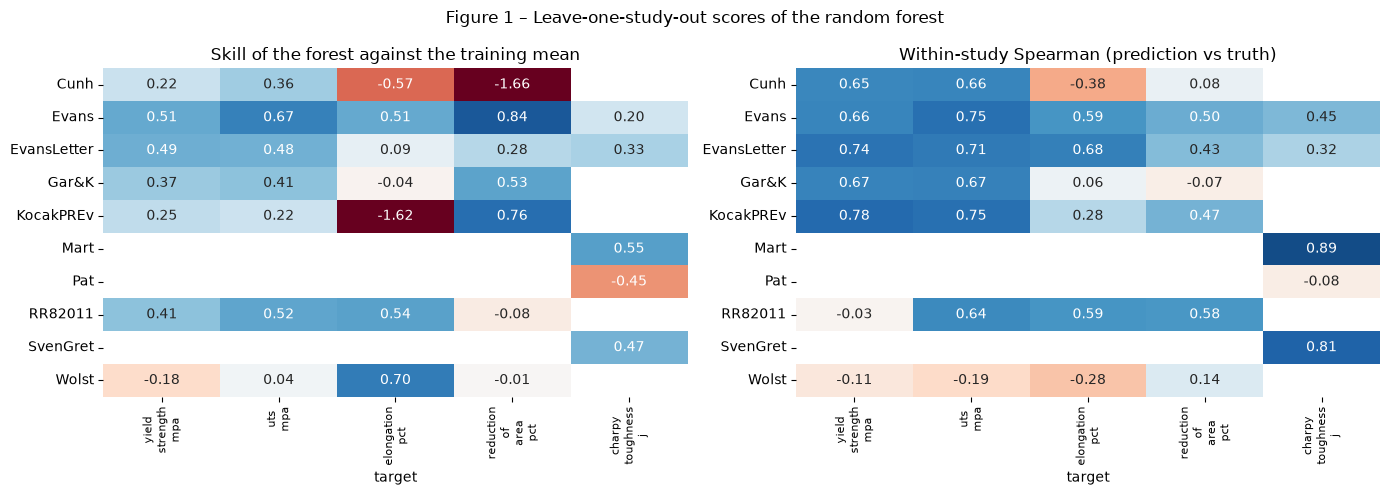

In [4]:
per_study = per_study_scores(results)
per_study.to_csv(RESULTS_DIR / "03_loso_scores.csv", index=False)
forest = per_study[per_study["model"] == "random forest"]
mean_model = per_study[per_study["model"] == "global_mean"]

skill = forest.pivot(index="study", columns="target", values="skill")[TARGETS]
rho = forest.pivot(index="study", columns="target", values="within_rho")[TARGETS]
n_rows = forest.pivot(index="study", columns="target", values="n_test")[TARGETS]
print("rows scored per study and target:")
print(n_rows.fillna(0).astype(int).to_string())
print("\nstudies where the forest beats the training mean (skill > 0), per target:")
print(((skill > 0).sum().astype(str) + " of " + skill.notna().sum().astype(str)).to_string())

bias = pd.DataFrame({"|bias| forest": forest.groupby("target")["bias"].apply(lambda s: s.abs().mean()),
                     "|bias| training mean": mean_model.groupby("target")["bias"].apply(lambda s: s.abs().mean())}).round(1)
print("\nmean |bias| over held-out studies:")
print(bias.loc[TARGETS].to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(skill, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Skill of the forest against the training mean")
sns.heatmap(rho, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1, ax=axes[1], cbar=False)
axes[1].set_title("Within-study Spearman (prediction vs truth)")
for ax in axes:
    ax.set_xticklabels([t.replace("_", "\n") for t in TARGETS], fontsize=8)
    ax.set_ylabel("")
fig.suptitle("Figure 1 \u2013 Leave-one-study-out scores of the random forest")
plt.tight_layout()
fig.savefig(FIG / "fig01_loso_skill_and_within_rho.png", dpi=150)
plt.show()

**Your conclusions:**

- **Strength transfers to unseen studies.** The forest beats the training mean on 6 of 7 studies for yield strength (skill 0.22-0.51; only Wolst, -0.18) and on 7 of 7 for UTS (0.04-0.67). Its mean level error is also smaller than that of the training mean: |bias| 25 vs 37 MPa (yield strength) and 26 vs 40 MPa (UTS).
- **It follows the variations inside a study it has never seen**: the within-study Spearman is 0.65-0.78 in five of the seven studies for yield strength and 0.64-0.75 in six of seven for UTS (medians 0.66 and 0.67). The failures are `Wolst` (-0.11 / -0.19; 23 rows) and `RR82011` on yield strength only (-0.03, while its UTS is 0.64).
- **Ductility is less reliable.** Elongation beats the mean in 4 of 7 studies (`Cunh` -0.57, `KocakPREv` -1.62, `Gar&K` -0.04 do not) with a median within-study Spearman of 0.28; reduction of area also in 4 of 7 (`Cunh` -1.66) with a median of 0.43. Part of the negative values comes from studies with a narrow spread (elongation in `KocakPREv` has a standard deviation of 1.8), where the training mean is already close and any error looks large.
- **Charpy toughness**: 4 of 5 studies positive (`Mart` 0.55, `SvenGret` 0.47, `EvansLetter` 0.33, `Evans` 0.20), `Pat` -0.45 (within-study Spearman -0.08). Only five studies, and the test temperature is a feature.
- **`Evans` (42% of the rows) is well predicted on every target** (0.51, 0.67, 0.51, 0.84, 0.20), so any average weighted by rows is dominated by it; this per-study table weights every study equally.
- **Caveats**: studies of 21-32 rows give noisy scores; the explanation of why `Wolst` or `Cunh` fail is not established and they should be inspected before any conclusion about measurement protocols.

### 1.4 Why the first ridge was worse than the mean

In [5]:
spec = feature_spec(clean, "yield_strength_mpa")
X, y = clean[spec.columns], clean["yield_strength_mpa"]
labeled = y.notna().to_numpy()
studies = sorted(clean["source"].value_counts()[lambda s: s >= 20].index)
rows = []
for study, (train, test) in zip(studies, make_folds(clean, "loso")):
    train, test = train[labeled[train]], test[labeled[test]]
    if len(test) < 20:
        continue
    pre = build_preprocessor("linear", spec, clip=None).fit(X.iloc[train])      # as before the fix
    held_out = pre.transform(X.iloc[test]).abs().max().sort_values(ascending=False)
    rows.append({"held-out study": study, "largest |scaled value| in training": round(pre.transform(X.iloc[train]).abs().max().max()),
                 "largest on the held-out study": round(held_out.iloc[0]), "column": held_out.index[0]})
print(f"Without the clip (the bound is now {SCALED_CLIP:g}):")
print(pd.DataFrame(rows).to_string(index=False))

linear = per_study[per_study["model"].str.startswith("ridge")]
effect = linear.groupby(["target", "model"])["skill"].agg(mean_skill="mean", share_positive=lambda s: (s > 0).mean()).round(2)
print("\nleave-one-study-out skill of the two ridge versions:")
print(effect.to_string())

Without the clip (the bound is now 5):
held-out study  largest |scaled value| in training  largest on the held-out study           column
          Cunh                                 995                            195      nb_conc_ppm
         Evans                                 170                            119       cr_conc_wt
   EvansLetter                                 950                             48      nb_conc_ppm
         Gar&K                                1198                            608        v_conc_wt
     KocakPREv                                1162                            162      ti_conc_ppm
       RR82011                                 960                            100 interpass_temp_c
         Wolst                                 860                            100 interpass_temp_c

leave-one-study-out skill of the two ridge versions:
                                                                 mean_skill  share_positive
target                m

**Your conclusions:**

- **The scaled features reached hundreds or thousands.** `RobustScaler` divides by the interquartile range of the median-filled column. For variables that are missing in more than half the rows (Nb, Sb, Cr) or concentrated on one value (interpass temperature, 64% of rows at 200 C) that range is zero, scikit-learn then divides by 1, and the variable stays in its raw unit. The largest scaled value was 170-1198 on the training rows and still 48-608 on a held-out study (V in `Gar&K` 608, Nb in `Cunh` 195, Ti in `KocakPREv` 162, Cr in `Evans` 119). A ridge extrapolates wildly on such values.
- **Fix applied in `src`**: the linear preprocessor clips the scaled numeric features to [-5, 5] (`SCALED_CLIP`), and `GroupTunedRidge` chooses the penalty among 1, 10, 100 and 1000 by cross-validation over whole studies of the training rows, so the scored study never takes part in the choice.
- **Leave-one-study-out skill, before -> after**: yield strength -1.69 -> +0.01, UTS -0.69 -> +0.15, elongation -1.47 -> -0.38, reduction of area -1.62 -> -0.23, Charpy -2.46 -> -0.02. The defect is gone (the ridge no longer extrapolates wildly), but a linear model brings little on a new study: about the mean for yield strength and Charpy, a modest gain for UTS, still below the mean for the ductility targets.
- **On the earlier figure**: a manual search over four settings on the scored studies gave +0.09 on yield strength; with the penalty chosen inside the training data it is +0.01. The first number was optimistic, as flagged at the time.
- **Tested but not adopted**: filling by scaling first then using 0, and dropping the poorly reported variables to avoid any NaN. The first gives no gain; the second hurts yield strength and UTS (the alloy elements carry the transferable signal) and helps only reduction of area and Charpy on 4 studies.


## 2. Next sections

To do, in this order, once the reading above is agreed:

1. a model zoo (Lasso, k-NN, SVR, gradient boosting, MLP) with hyperparameters tuned **inside the training fold**;
2. the four tensile properties modeled jointly on their 650 complete rows, against four separate models;
3. the third protocol grouped by input fingerprint (needs agreement, see `doc/03_project_structure.md`);
4. feature importance, with the within-study coefficient of notebook 02 as the reference for plausibility.